# **1. SQLite**
SQLite는 별도의 데이터베이스 서버를 설치하지 않고 파일로 사용하는 데이터베이스

In [2]:
import sqlite3
from pathlib import Path

In [3]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
simple_path = DATA_DIR / "hello.db"

In [4]:
conn_simple = sqlite3.connect(simple_path)
print('연결성공:', simple_path.resolve())

연결성공: C:\heeseung\14_Agent\data\hello.db


In [5]:
# SQLite에서는 INT가 아니라 INTEGER
# execute: DDL, DML, TCL 전부 사용 가능
conn_simple.execute("""
CREATE TABLE students(
    id INTEGER PRIMARY KEY,
    name VARCHAR(20) NOT NULL,
    score INTEGER NOT NULL)
""")

# extension에서 SQLite 검색 -> SQLite Viewer(Florian Klampfer) 다운  <- 파이썬에 있는 sqlite를 사용해서 SQLite 다운 X

In [6]:
# 내가 한 거 테이블 잘 못 만들었음
conn_simple.execute("""
    DROP TABLE studets
""")


OperationalError: no such table: studets

In [7]:
students = [(1, "김사과", 90), (2, "반하나", 85), (3, "오렌지", 95)]

# executemany: 동일한 쿼리문을 여러 데이터에 반복 실행
conn_simple.executemany("INSERT INTO students (id, name, score) VALUES (?, ?, ?)", students)

# commit을 써서 저장(영구적으로 반영한 다는 말)
conn_simple.commit()
print("학생 데이터 저장 완료")

학생 데이터 저장 완료


In [8]:
# fetchall은 모든 행을 가져오는 함수
# (90,))은 90 이상의 점수를 튜플 형식으로 가져오려고. 90은 앞에 ?에 들어감
# 만약 (90)이면 int형식
rows = conn_simple.execute("SELECT name, score FROM students WHERE score >= ? order by score DESC", (90,)).fetchall()
for name, score in rows:
    print(name, score)

오렌지 95
김사과 90


In [9]:
import pandas as pd

![차이점](./images/read_sql_query와execute의_차이.png)

In [10]:
pd.read_sql_query("SELECT * FROM students ORDER BY score DESC", conn_simple)

,id,name,score
0,3,오렌지,95
1,1,김사과,90
2,2,반하나,85


In [11]:
conn_simple.close()
print("연습용 DB 연결 종료")

연습용 DB 연결 종료


- 음악 판매 디비? 데이터셋? 링크 누르면 바로 다운됨
https://storage.googleapis.com/benchmarks-artifacts/chinook/Chinook.db

In [12]:
import requests

In [13]:
# Chinook.db 파일을 다운로드하고 SQLite 데이터베이스에 연결하는 코드

path = DATA_DIR / "Chinook.db"

# 데이터베이스 파일이 존재하지 않을 경우에만 다운로드
# exists(): 해당 경로에 파일 또는 폴더가 존재하는지 확인 (bool)
if not path.exists():
    url = "https://storage.googleapis.com/benchmarks-artifacts/chinook/Chinook.db"

    # GET 요청으로 데이터베이스 파일 다운로드
    # timeout=30: 서버 응답을 최대 30초 동안 기다리도록 설정
    # response: HTTP 응답 정보를 저장한 Response 객체
    response = requests.get(url, timeout=30)

    # HTTP 요청이 실패한 경우 예외 발생
    # raise_for_status(): 4xx, 5xx 상태 코드에서 HTTPError 발생
    response.raise_for_status()

    # 다운로드한 파일의 바이너리 데이터를 지정한 경로에 저장
    # response.content: 다운로드한 파일의 바이너리 데이터 (bytes)
    # write_bytes(): 바이너리 데이터를 파일에 기록하는 메서드
    path.write_bytes(response.content)

# resolve(): 상대 경로를 절대 경로로 변환
print("DB 파일: ", path.resolve())

# conn: SQLite 데이터베이스 연결 객체 (sqlite3.Connection)
conn = sqlite3.connect(path)

print("연결 성공")

DB 파일:  C:\heeseung\14_Agent\data\Chinook.db
연결 성공


In [14]:
tables = conn.execute("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name").fetchall()
print([name for (name,) in tables])

['Album', 'Artist', 'Customer', 'Employee', 'Genre', 'Invoice', 'InvoiceLine', 'MediaType', 'Playlist', 'PlaylistTrack', 'Track']


In [15]:
pd.read_sql_query("SELECT * FROM customer limit 5", conn)

,CustomerId,FirstName,LastName,Company,Address,City,State,Country,PostalCode,Phone,Fax,Email,SupportRepId
0,1,Luís,Gonçalves,Embraer - Empresa Brasileira de Aeronáutica S.A.,"Av. Brigadeiro Faria Lima, 2170",São José dos Campos,SP,Brazil,12227-000,+55 (12) 3923-5555,+55 (12) 3923-5566,luisg@embraer.com.br,3
1,2,Leonie,Köhler,NaN,Theodor-Heuss-Straße 34,Stuttgart,NaN,Germany,70174,+49 0711 2842222,NaN,leonekohler@surfeu.de,5
2,3,François,Tremblay,NaN,1498 rue Bélanger,Montréal,QC,Canada,H2G 1A7,+1 (514) 721-4711,NaN,ftremblay@gmail.com,3
3,4,Bjørn,Hansen,NaN,Ullevålsveien 14,Oslo,NaN,Norway,0171,+47 22 44 22 22,NaN,bjorn.hansen@yahoo.no,4
4,5,František,Wichterlová,JetBrains s.r.o.,Klanova 9/506,Prague,NaN,Czech Republic,14700,+420 2 4172 5555,+420 2 4172 5555,frantisekw@jetbrains.com,4


In [16]:
pd.read_sql_query("SELECT * FROM invoice limit 5", conn)

,InvoiceId,CustomerId,InvoiceDate,BillingAddress,BillingCity,BillingState,BillingCountry,BillingPostalCode,Total
0,1,2,2009-01-01 00:00:00,Theodor-Heuss-Straße 34,Stuttgart,NaN,Germany,70174,1.98
1,2,4,2009-01-02 00:00:00,Ullevålsveien 14,Oslo,NaN,Norway,0171,3.96
2,3,8,2009-01-03 00:00:00,Grétrystraat 63,Brussels,NaN,Belgium,1000,5.94
3,4,14,2009-01-06 00:00:00,8210 111 ST NW,Edmonton,AB,Canada,T6G 2C7,8.91
4,5,23,2009-01-11 00:00:00,69 Salem Street,Boston,MA,USA,2113,13.86


In [17]:
# 주문별 고객 이름과 주문 금액(customer, invoice)
# SELECT LastName, Total FROM customer AS c, invoice AS t WHERE c.CustomerId == t.CustomerId

pd.read_sql_query("""
    SELECT c.firstname, c.lastname, i.total FROM customer AS c JOIN invoice AS i ON c.customerid = i.customerid limit 10
""", conn)


,FirstName,LastName,Total
0,Leonie,Köhler,1.98
1,Bjørn,Hansen,3.96
2,Daan,Peeters,5.94
3,Mark,Philips,8.91
4,John,Gordon,13.86
5,Fynn,Zimmermann,0.99
6,Niklas,Schröder,1.98
7,Dominique,Lefebvre,1.98
8,Wyatt,Girard,3.96
9,Hugh,O'Reilly,5.94


In [18]:
# 국가별 주문 총액 상위 5개
# pd.read_sql_query("""
#     SELECT billingcountry FROM invoice GROUP BY billingcountry ORDER BY count(billingcountry) DESC LIMIT 5
# """, conn)

pd.read_sql_query("""
    SELECT billingcountry, round(sum(total), 2) AS revenue FROM invoice GROUP BY billingcountry ORDER BY revenue DESC LIMIT 5
""", conn)

,BillingCountry,revenue
0,USA,523.06
1,Canada,303.96
2,France,195.10
3,Brazil,190.10
4,Germany,156.48


# **2. LangChain으로 연결**

In [19]:
from langchain_community.utilities import SQLDatabase

C:\Users\Administrator\AppData\Local\Temp\ipykernel_5356\1266060898.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import SQLDatabase


In [20]:
# SQLite 데이터베이스를 LangChain의 SQLDatabase 객체로 연결하고 테이블 정보를 확인하는 코드


# SQLDatabase.from_uri(): 데이터베이스 연결 주소를 이용해 SQLDatabase 객체 생성
db = SQLDatabase.from_uri(f"sqlite:///{path.resolve().as_posix()}")


print("DB 종류: ", db.dialect)

# get_usable_table_names(): 사용 가능한 테이블 이름을 리스트로 반환 (list[str])
print("테이블: ", db.get_usable_table_names())

# get_table_info(): 지정한 테이블의 구조 및 관련 정보를 문자열로 반환 (str)
# ['Invoice']: 정보를 확인할 테이블 이름 리스트 (list[str])
# [:1200]: 리스트의 앞에서 최대 1200개 요소를 선택 (현재는 요소가 1개)
print("\nInvoice 테이블 구조 일부: ")
print(db.get_table_info(['Invoice'][:1200]))

DB 종류:  sqlite
테이블:  ['Album', 'Artist', 'Customer', 'Employee', 'Genre', 'Invoice', 'InvoiceLine', 'MediaType', 'Playlist', 'PlaylistTrack', 'Track']

Invoice 테이블 구조 일부: 

CREATE TABLE "Invoice" (
	"InvoiceId" INTEGER NOT NULL, 
	"CustomerId" INTEGER NOT NULL, 
	"InvoiceDate" DATETIME NOT NULL, 
	"BillingAddress" NVARCHAR(70), 
	"BillingCity" NVARCHAR(40), 
	"BillingState" NVARCHAR(40), 
	"BillingCountry" NVARCHAR(40), 
	"BillingPostalCode" NVARCHAR(10), 
	"Total" NUMERIC(10, 2) NOT NULL, 
	PRIMARY KEY ("InvoiceId"), 
	FOREIGN KEY("CustomerId") REFERENCES "Customer" ("CustomerId")
)

/*
3 rows from Invoice table:
InvoiceId	CustomerId	InvoiceDate	BillingAddress	BillingCity	BillingState	BillingCountry	BillingPostalCode	Total
1	2	2009-01-01 00:00:00	Theodor-Heuss-Straße 34	Stuttgart	None	Germany	70174	1.98
2	4	2009-01-02 00:00:00	Ullevålsveien 14	Oslo	None	Norway	0171	3.96
3	8	2009-01-03 00:00:00	Grétrystraat 63	Brussels	None	Belgium	1000	5.94
*/


In [21]:
# as_posix: 경로 구분자를 / 형태로 변환 <- 사용하는 이유는 윈도우와 리눅스에서 둘 다 유용하게 쓰임
db = SQLDatabase.from_uri(f"sqlite:///{path.resolve().as_posix()}")

# dialect: 연결된 데이터베이스의 종류를 나타내는 속성 (str)
print("DB 종류: ", db.dialect)

# get_usable_table_names(): 사용 가능한 테이블 이름을 리스트로 반환 (list[str])
print("테이블: ", db.get_usable_table_names())
print("\nInvoice 테이블 구조 일부: ")

# Invoice 테이블 정보를 조회하고 앞에서 1200글자만 출력
print(db.get_table_info(['Invoice'])[:1200])

DB 종류:  sqlite
테이블:  ['Album', 'Artist', 'Customer', 'Employee', 'Genre', 'Invoice', 'InvoiceLine', 'MediaType', 'Playlist', 'PlaylistTrack', 'Track']

Invoice 테이블 구조 일부: 

CREATE TABLE "Invoice" (
	"InvoiceId" INTEGER NOT NULL, 
	"CustomerId" INTEGER NOT NULL, 
	"InvoiceDate" DATETIME NOT NULL, 
	"BillingAddress" NVARCHAR(70), 
	"BillingCity" NVARCHAR(40), 
	"BillingState" NVARCHAR(40), 
	"BillingCountry" NVARCHAR(40), 
	"BillingPostalCode" NVARCHAR(10), 
	"Total" NUMERIC(10, 2) NOT NULL, 
	PRIMARY KEY ("InvoiceId"), 
	FOREIGN KEY("CustomerId") REFERENCES "Customer" ("CustomerId")
)

/*
3 rows from Invoice table:
InvoiceId	CustomerId	InvoiceDate	BillingAddress	BillingCity	BillingState	BillingCountry	BillingPostalCode	Total
1	2	2009-01-01 00:00:00	Theodor-Heuss-Straße 34	Stuttgart	None	Germany	70174	1.98
2	4	2009-01-02 00:00:00	Ullevålsveien 14	Oslo	None	Norway	0171	3.96
3	8	2009-01-03 00:00:00	Grétrystraat 63	Brussels	None	Belgium	1000	5.94
*/


In [22]:
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

In [23]:
load_dotenv(".env")

True

In [24]:
MODEL = os.getenv("OPENAI_MODEL", "gpt-5.6-luna")
llm = ChatOpenAI(model = MODEL, temperature=0)

In [25]:
from langchain_core.messages import HumanMessage

In [26]:
# 데이터베이스의 테이블 구조를 가져와 자연어 질문을 SQL 쿼리로 변환하기 위한 프롬프트 생성

# get_table_info(): 지정한 테이블의 구조 정보를 문자열로 반환하는 메서드
# schema: 테이블 자체가 아니라 테이블의 구조를 정의한 설계도
# 즉, 테이블의 컬럼, 자료형, 제약조건 등을 정의한 구조

schema = db.get_table_info(['Invoice', 'Customer', 'Employee'])

question = "2009년에 고객 담당 직원별 매출 합계 상위 3명을 알려줘"

# {schema}: Invoice, Customer, Employee 테이블의 구조 정보 삽입
# {question}: 사용자 질문 삽입

prompt = f"""
    SQLite SELECT 쿼리 하나만 작성하세요. 코드불록 없이 SQL만 출력하세요.
    스키마:
    {schema}
    질문: {question}
    조건: Invoice.Total의 합계를 사용하고 InvoiceDate는 2009년으로 제한합니다.
    고객의 SuppertRepId를 담당 직원으로 정의합니다. 결과는 최대 3행.
    INSERT/UPDATE/DELETE/DROP 등 데이터 변경문은 절대 금지합니다.
"""

In [27]:
raw_sql = llm.invoke([HumanMessage(content=prompt)]).content
print(raw_sql)

SELECT e."FirstName", e."LastName", SUM(i."Total") AS "TotalSales"
FROM "Invoice" i
JOIN "Customer" c ON i."CustomerId" = c."CustomerId"
JOIN "Employee" e ON c."SupportRepId" = e."EmployeeId"
WHERE i."InvoiceDate" >= '2009-01-01'
  AND i."InvoiceDate" < '2010-01-01'
GROUP BY e."EmployeeId", e."FirstName", e."LastName"
ORDER BY "TotalSales" DESC
LIMIT 3;


In [28]:
import re

In [ ]:
# 정리 필요

# SQL 쿼리를 검사하여 허용된 조회문만 실행하고 결과를 DataFrame으로 반환하는 함수

# 소프트웨어적으로 함수를 한 번 들리는게 보안적으로 좋음
# max_rows: 최대 조회할 행의 개수 (int, 기본값 20)
def read_only_query(sql: str, max_rows=20):

    # SQL 문자열 양쪽의 공백과 마크다운 코드블록(```sql, ```) 제거
    # re.sub(): 정규표현식과 일치하는 문자열을 다른 문자열로 치환하는 함수
    # ^: 문자열 시작, $: 문자열 끝
    # (?:sql)?: sql이라는 문자열이 0번 또는 1번 나타나는지 확인
    # \s*: 공백 문자가 0개 이상 있는지 확인
    # strip(): 문자열 양쪽 공백 제거
    # flags=re.I: 영문 대소문자 구분 없이 검사
    sql = re.sub(r"^```(?:sql)?\s*|\s*```$", "", sql.strip(), flags=re.I).strip()

    # SELECT 또는 WITH로 시작하지 않으면 오류 발생
    # re.match(): 문자열 시작 부분이 정규표현식과 일치하는지 검사
    # \b: 단어의 경계를 의미
    # ValueError: 잘못된 값이 전달되었을 때 발생시키는 예외
    if not re.match(r"^(SELECT|WITH)\b", sql, flags=re.I):
        raise ValueError("SELECT 또는 WITH 형태의 단일 쿼리만 허용합니다.")

    # 데이터 변경 및 데이터베이스 구조 변경 관련 SQL 키워드 검사
    # re.search(): 문자열 전체에서 정규표현식과 일치하는 부분 검색
    # 아래 금지된 키워드가 발견되면 오류 발생
    if re.search(r"\b(INSERT|UPDATE|DELETE|DROP|ALTER|CREATE|ATTACH|DETACH|PRAGMA|REPLACE|VACUUM)\b", sql, flags=re.I):
        raise ValueError("허용되지 않는 SQL 키워드가 있습니다.")

    # 검사를 통과한 SQL 쿼리 실행
    # cur: SQL 실행 결과에 접근하는 Cursor 객체 (sqlite3.Cursor)
    cur = conn.execute(sql)

    # 조회 결과의 컬럼 이름 추출
    # cur.description: 조회 결과의 컬럼 정보를 저장한 시퀀스
    # d[0]: 각 컬럼 정보에서 컬럼 이름 추출 (str)
    # columns: 컬럼 이름이 저장된 리스트 (list[str])
    columns = [d[0] for d in cur.description]

    # 조회 결과 중 최대 max_rows개의 행을 가져와 DataFrame으로 반환
    # fetchmany(max_rows): 최대 max_rows개의 행을 리스트로 반환 (list[tuple])
    # columns=columns: DataFrame의 컬럼 이름 지정
    # pd.DataFrame(): 데이터를 pandas DataFrame으로 변환
    return pd.DataFrame(cur.fetchmany(max_rows), columns=columns)


try:
    # read_only_query(): SQL 검사 후 조회 결과를 DataFrame으로 반환
    # display(): DataFrame을 표 형태로 출력
    display(read_only_query(raw_sql))

# exc: 발생한 예외 객체 (Exception)
except Exception as exc:
    # type(exc).__name__: 발생한 예외의 클래스 이름 (str)
    # str(exc): 예외의 상세 메시지 (str)
    print(type(exc).__name__, str(exc))

,FirstName,LastName,TotalSales
0,Steve,Johnson,164.34
1,Margaret,Park,161.37
2,Jane,Peacock,123.75


질문 > SQL > 검증 > 실행

# **3. LangChain Toolkit**
- Tool : LLM이 호출할 수 있게 만든 함수
SQL Toolkit은 테이블 목록, 스키마 조회, 쿼리 검사, 실행 도구 등이 있음

In [30]:
from langchain_community.agent_toolkits import SQLDatabaseToolkit

In [31]:
toolkit = SQLDatabaseToolkit(db=db, llm=llm)
for tool in toolkit.get_tools():
    print(tool.name, ':', tool.description[:100])

sql_db_query : Input to this tool is a detailed and correct SQL query, output is a result from the database. If the
sql_db_schema : Input to this tool is a comma-separated list of tables, output is the schema and sample rows for tho
sql_db_list_tables : Input is an empty string, output is a comma-separated list of tables in the database.
sql_db_query_checker : Use this tool to double check if your query is correct before executing it. Always use this tool bef


In [32]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [33]:
class SQLState(TypedDict, total=False):
    question: str
    sql: str
    result: str
    answer: str
    error: str

def generate_sql(state: SQLState):
    p = f"""다음 SQLite 스키마만 사용해 SELECT SQL 하나를 만드세요.
    코드블록 없이 SQL만 출력하고 LIMIT 10을 포함하세요.
    스키마: {schema}
    질문: {state['question']}"""
    return {"sql": llm.invoke(p).content}

def execute_sql(state: SQLState):
    try: 
        df = read_only_query(state['sql'], max_rows=10) # 함수에 sql을 넣어서 실행
        return {"result": df.to_json(orient='records', force_ascii=False), "error": ""} # json형태로 데이터프레임을 만들어 결과를 리턴
    except Exception as e:
        return {"result": "", "error": str(e)}

def make_answer(state: SQLState):
    # 데이터를 가져옴
    if state.get("error"): # 에러가 있다면
        return {"answer": "쿼리 실행 실패: " + state['error']}
    msg = f'질문: {state['question']}\n조회 결과: {state['result']}\n조회 결과에 근거하여 한국어로 답하세요'
    return {"answer": llm.invoke(msg).content}

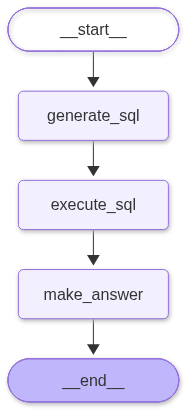

In [34]:
# 그래프 만들기
builder = StateGraph(SQLState)
builder.add_node("generate_sql", generate_sql)
builder.add_node("execute_sql", execute_sql)
builder.add_node("make_answer", make_answer)
builder.add_edge(START, "generate_sql")
builder.add_edge("generate_sql", "execute_sql")
builder.add_edge("execute_sql", "make_answer")
builder.add_edge("make_answer", END)
sql_graph = builder.compile()
sql_graph

In [35]:
result = sql_graph.invoke({"question": "2009년 고객 담당 직원별 매출 합계 1위는 누구인가요?"})
print("생성 SQL: ", result['sql'])
print("조회 결과: ", result['result'])
print("최종 답변: ", result['answer'])

생성 SQL:  SELECT e."EmployeeId", e."FirstName", e."LastName", SUM(i."Total") AS "TotalSales"
FROM "Invoice" i
JOIN "Customer" c ON i."CustomerId" = c."CustomerId"
JOIN "Employee" e ON c."SupportRepId" = e."EmployeeId"
WHERE strftime('%Y', i."InvoiceDate") = '2009'
GROUP BY e."EmployeeId", e."FirstName", e."LastName"
ORDER BY "TotalSales" DESC
LIMIT 10;
조회 결과:  [{"EmployeeId":5,"FirstName":"Steve","LastName":"Johnson","TotalSales":164.34},{"EmployeeId":4,"FirstName":"Margaret","LastName":"Park","TotalSales":161.37},{"EmployeeId":3,"FirstName":"Jane","LastName":"Peacock","TotalSales":123.75}]
최종 답변:  2009년 고객 담당 직원별 매출 합계 1위는 **Steve Johnson(직원 ID 5)**이며, 총매출은 **164.34**입니다.
